# Домашнее задание 2: база знаний и память агента


In [ ]:
%pip install -q requests pydantic python-dotenv pandas matplotlib numpy pymilvus pypdf

In [1]:
import os, re, sys, json, time, hashlib, threading
from pathlib import Path
from dataclasses import dataclass, field
from concurrent.futures import ThreadPoolExecutor
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pydantic import BaseModel, Field
from pymilvus import MilvusClient

try:
    from dotenv import load_dotenv
    load_dotenv()
except ImportError:
    pass

assert os.getenv("OPENROUTER_API_KEY"), "нет ключа: положите его в .env рядом с ноутбуком или в Kaggle Secrets"

CHAT_URL = "https://openrouter.ai/api/v1/chat/completions"
EMBED_URL = "https://openrouter.ai/api/v1/embeddings"
HEADERS = {"Authorization": f"Bearer {os.environ['OPENROUTER_API_KEY']}", "X-Title": "agents-course-seminar02"}
MODELS = {"cheap": "openai/gpt-4o-mini", "mid": "anthropic/claude-haiku-4.5", "strong": "anthropic/claude-sonnet-4.6"}
EMBED_MODEL, DIM = "openai/text-embedding-3-small", 512
COLORS = {"violet": "#5436A3", "amber": "#F09000", "teal": "#00838F", "red": "#C43C3C", "grey": "#787882"}
DATA = next((p for p in [Path("data"), Path("/kaggle/input/seminar02-data"), Path("/kaggle/input/seminar02-data/data")]
             if (p / "corpus_2026.jsonl").exists()), Path("data"))
Path("img").mkdir(exist_ok=True)


@dataclass
class Ledger:
    calls: list = field(default_factory=list)
    local: threading.local = field(default_factory=threading.local)

    def add(self, tag, model, usage, seconds=0.0):
        cost = usage.get("cost") or 0.0
        self.calls.append({"tag": tag, "model": model.split("/")[-1], "prompt": usage.get("prompt_tokens", 0),
                           "completion": usage.get("completion_tokens", 0), "cost": cost, "seconds": round(seconds, 2)})
        self.local.spent = self.mine + cost
        return cost

    @property
    def total(self):
        return sum(c["cost"] for c in self.calls)

    @property
    def mine(self):
        return getattr(self.local, "spent", 0.0)

    def table(self):
        frame = pd.DataFrame(self.calls, columns=["tag", "model", "prompt", "completion", "cost", "seconds"])
        return frame.groupby(["tag", "model"]).agg(calls=("cost", "size"), prompt=("prompt", "sum"),
                                                                      completion=("completion", "sum"), cost=("cost", "sum")).round(5)


ledger = Ledger()


def post_with_retry(url, body, attempts=5):
    problem = "нет ответа"
    for attempt in range(attempts):
        try:
            r = requests.post(url, json=body, headers=HEADERS, timeout=120)
            if r.status_code == 200:
                return r.json()
            problem = f"HTTP {r.status_code}: {r.text[:200]}"
            if r.status_code not in (429, 500, 502, 503, 504):
                break
        except requests.RequestException as e:
            problem = type(e).__name__
        time.sleep(2.0 * (attempt + 1))
    raise RuntimeError(problem)


def chat(messages, model, tools=None, tag="chat"):
    body = {"model": model, "messages": messages, "temperature": 0, "usage": {"include": True}}
    if tools:
        body["tools"] = tools
    started = time.perf_counter()
    data = post_with_retry(CHAT_URL, body)
    ledger.add(tag, model, data.get("usage") or {}, time.perf_counter() - started)
    return data["choices"][0]["message"]


def load_jsonl(name):
    return [json.loads(line) for line in (DATA / name).read_text(encoding="utf-8").splitlines() if line.strip()]

## Шаг 1. Корпус и вопросы

28 страниц Википедии «2026 in ...», 149 вопросов с цитатой (`evidence`), 10 вопросов без ответа в `data/unanswerable_2026.jsonl`.

In [2]:
corpus, tasks = load_jsonl("corpus_2026.jsonl"), load_jsonl("fresh_2026.jsonl")
len(corpus), sum(len(p["text"]) for p in corpus), len(tasks), tasks[0]

(28,
 882018,
 149,
 {'id': 'fresh-0',
  'source': 'fresh',
  'question': 'On what date did Ukraine boycott the closing ceremony of the 2026 Winter Paralympics?',
  'answer': '15 March',
  'evidence': '15 March – Ukraine boycotts the closing ceremony of the 2026 Winter Paralympics in Italy in protest over Russian athletes being allowed to compete under the Russian flag after the lifting of sanctions imposed over the Russian invasion in 2022.',
  'page': '2026 in Ukraine',
  'url': 'https://en.wikipedia.org/wiki/2026_in_Ukraine',
  'agent_ok': False})

## Шаг 2. Нарезка, эмбеддинги, индекс и качество поиска

### 2.1 Две нарезки: по строкам (осмысленная) и по 400 символов (наивная)

In [3]:
def chunk_lines(page):
    chunks, section = [], ""
    for line in page["text"].splitlines():
        line = " ".join(line.split())
        if line.startswith("="):
            section = line.strip('= ')
        elif len(line) > 40:
            chunks.append({"page": page["page"], "section": section, "url" : page["url"], "text": line})
    return chunks



In [4]:
def chunk_chars(page, size=400):
    text = " ".join(page["text"].split())
    return [{"page": page["page"], "section": "", "url": page["url"], "text": text[i:i + size]} for i in range(0, len(text), size)]

line_chunks = [c for p in corpus for c in chunk_lines(p)]
char_chunks = [c for p in corpus for c in chunk_chars(p)]
len(line_chunks), len(char_chunks), line_chunks[100]

(5986,
 2213,
 {'page': '2026',
  'section': 'April',
  'url': 'https://en.wikipedia.org/wiki/2026',
  'text': '2026 Beninese presidential election: Independent candidate Romuald Wadagni wins in a landslide with over 94% of the vote.'})

In [5]:
def torn(task):
    words = re.findall(r"\w+", task["evidence"].lower())
    head, tail = " ".join(words[:6]), " ".join(words[-6:])
    parts = [c["text"] for c in char_chunks if c["page"] == task["page"]
             and (head in " ".join(re.findall(r"\w+", c["text"].lower())) or tail in " ".join(re.findall(r"\w+", c["text"].lower())))]
    return parts if len(parts) == 2 else None

example = next(t for t in tasks if torn(t))
print("вопрос:", example["question"], "| ответ:", example["answer"])
for n, part in enumerate(torn(example), 1):
    print(f"кусок {n}: ...{part[-160:]}" if n == 1 else f"кусок {n}: {part[:160]}...")

вопрос: On what date did Ukraine boycott the closing ceremony of the 2026 Winter Paralympics? | ответ: 15 March
кусок 1: ...ic partnership agreement in the defense and energy sectors. 15 March – Ukraine boycotts the closing ceremony of the 2026 Winter Paralympics in Italy in protest 
кусок 2: over Russian athletes being allowed to compete under the Russian flag after the lifting of sanctions imposed over the Russian invasion in 2022. 19 March – Forme...


### 2.2 Эмбеддинги с кэшем на диске

In [6]:
EMB = {}

def load_cache():
    for path in [DATA / "embeddings_512.npz", Path("emb_cache.npz")]:
        if path.exists():
            z = np.load(path)
            EMB.update({str(k): v.astype(np.float32) for k, v in zip(z["keys"], z["vectors"])})
    return len(EMB)

def save_cache():
    np.savez_compressed("emb_cache.npz", keys=np.array(list(EMB)), vectors=np.stack(list(EMB.values())).astype(np.float16))

def embed_batch(texts):
    started = time.perf_counter()
    data = post_with_retry(EMBED_URL, {"model": EMBED_MODEL, "input": texts, "dimensions": DIM})
    ledger.add("embed", EMBED_MODEL, data.get("usage") or {}, time.perf_counter() - started)
    return [row["embedding"] for row in data["data"]]

def key_of(text):
    return hashlib.sha1(text.encode("utf-8")).hexdigest()

load_cache()

9505

In [7]:
def embed_cached(texts):
    missing = list(dict.fromkeys(t for t in texts if key_of(t) not in EMB))
    for i in range(0, len(missing), 64):
        batch = missing[i:i+64]
        for text, vector in zip(batch, embed_batch(batch)):
            EMB[key_of(text)] = np.asarray(vector, dtype=np.float32)

    vectors = np.stack([EMB[key_of(t)] for t in texts])
    return vectors / np.linalg.norm(vectors, axis=1, keepdims=True)



In [8]:
def emb_text(chunk):
    return f"{chunk['page']}: {chunk['text']}"

line_vecs = embed_cached([emb_text(c) for c in line_chunks])
char_vecs = embed_cached([c["text"] for c in char_chunks])
q_vecs = embed_cached([t["question"] for t in tasks])
save_cache()
line_vecs.shape, char_vecs.shape, q_vecs.shape

((5986, 512), (2213, 512), (149, 512))

In [9]:
probe = embed_cached(["Who won the 2026 FIFA World Cup?", "Which country became world champion in football in 2026?", "What was the weather in Tokyo yesterday?"])
save_cache()
(probe @ probe.T).round(2), ledger.table()

(array([[1.  , 0.81, 0.07],
        [0.81, 1.  , 0.05],
        [0.07, 0.05, 1.  ]], dtype=float32),
                               calls  prompt  completion  cost
 tag   model                                                  
 embed text-embedding-3-small      1      54           0   0.0)

### 2.3 Поиск на numpy и кривая recall@k

In [10]:
def search_numpy(query_vec, vectors, k=5):
    similarities = vectors @ query_vec
    top = np.argsort(-similarities)[:k]
    return[(int(i), float(similarities[i])) for i in top]

In [11]:
NUMBERS = {word: str(n) for n, word in enumerate("zero one two three four five six seven eight nine ten eleven twelve".split())}

def norm(text):
    words = re.sub(r"\b(a|an|the)\b|[^\w\s]", " ", str(text).lower()).split()
    return " ".join(NUMBERS.get(w, w) for w in words)

def is_gold(chunk, task):
    if chunk["page"] != task["page"]:
        return False
    text, words = norm(chunk["text"]), norm(task["evidence"]).split()
    return norm(task["answer"]) in text and sum(w in text for w in words) >= 0.5 * len(words)

def recall_curve(chunks, vectors, ks=(1, 3, 5, 10, 20)):
    ranked = [[i for i, _ in search_numpy(q, vectors, max(ks))] for q in q_vecs]
    return {k: float(np.mean([any(is_gold(chunks[i], t) for i in r[:k]) for r, t in zip(ranked, tasks)])) for k in ks}

for i, score in search_numpy(q_vecs[0], line_vecs, 3):
    print(round(score, 3), "|", line_chunks[i]["page"], "|", line_chunks[i]["text"][:110])
tasks[0]["question"], tasks[0]["answer"]

0.821 | 2026 in Ukraine | 15 March – Ukraine boycotts the closing ceremony of the 2026 Winter Paralympics in Italy in protest over Russi
0.803 | 2026 in Ukraine | Ukraine boycotts the opening ceremony of the 2026 Winter Paralympics in Italy in protest over Russian athletes
0.674 | 2026 in Ukraine | 6–22 February – Ukraine at the 2026 Winter Olympics


('On what date did Ukraine boycott the closing ceremony of the 2026 Winter Paralympics?',
 '15 March')

,по строкам,по 400 символов
1,0.90,0.55
3,0.98,0.74
5,0.99,0.81
10,0.99,0.85
20,1.00,0.91


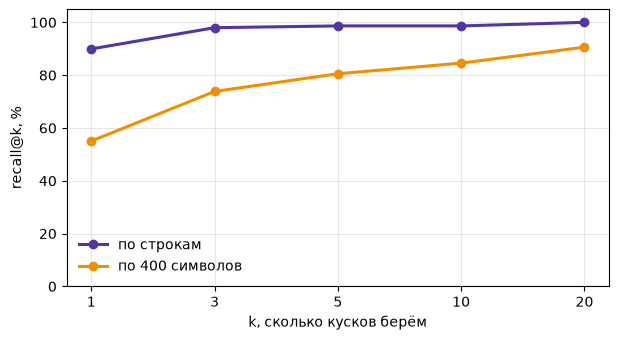

In [12]:
curves = {"по строкам": recall_curve(line_chunks, line_vecs), "по 400 символов": recall_curve(char_chunks, char_vecs)}
fig, ax = plt.subplots(figsize=(7, 3.6))
for (name, curve), color in zip(curves.items(), [COLORS["violet"], COLORS["amber"]]):
    ax.plot([str(k) for k in curve], [v * 100 for v in curve.values()], marker="o", lw=2.2, color=color, label=name)
ax.set_xlabel("k, сколько кусков берём"); ax.set_ylabel("recall@k, %"); ax.set_ylim(0, 105); ax.legend(frameon=False); ax.grid(alpha=0.3)
fig.savefig("img/recall.png", dpi=150, bbox_inches="tight")
pd.DataFrame(curves).round(2)

### 2.4 Гибрид: вектор + слова, слияние рангов RRF

In [13]:
def tokens(text):
    return re.findall(r"\w+", text.lower())

def build_keyword_index(texts):
    docs = [set(tokens(text)) for text in texts]
    df = {}
    for d in docs:
        for w in d:
            df[w] = df.get(w, 0) + 1
    return docs, {w: np.log(len(docs) / n) for w, n in df.items()}

def keyword_search(query, docs, idf, k=20):
    q = set(tokens(query))
    scores = np.array([sum(idf.get(w, 0.0) for w in q & d) for d in docs])
    return [int(i) for i in np.argsort(-scores)[:k]]

In [14]:
def rrf(rankings, k=5, K=60):
    scores = {}
    for ranking in rankings:
        for rank, idx in enumerate(ranking):
            scores[idx] = scores.get(idx, 0.0) + 1 / (K + rank + 1)

    return sorted(scores, key=scores.get, reverse=True)[:k]


,нарезка,поиск,recall@1,recall@5
0,по 400 символов,только вектор,0.55,0.81
1,по 400 символов,только слова,0.77,0.89
2,по 400 символов,гибрид RRF,0.72,0.87
3,по строкам,только вектор,0.90,0.99
4,по строкам,только слова,0.91,0.98
5,по строкам,гибрид RRF,0.91,1.00


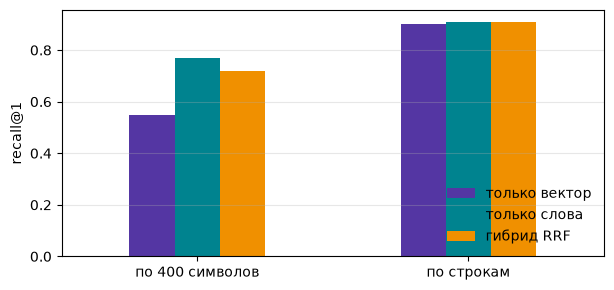

In [15]:
def recall_of(rankings, chunks, k=5):
    return float(np.mean([any(is_gold(chunks[i], t) for i in r[:k]) for r, t in zip(rankings, tasks)]))

rows = []
for cut, chunks, vectors, texts in [("по 400 символов", char_chunks, char_vecs, [c["text"] for c in char_chunks]),
                                    ("по строкам", line_chunks, line_vecs, [emb_text(c) for c in line_chunks])]:
    docs, idf = build_keyword_index(texts)
    by_vector = [[i for i, _ in search_numpy(q, vectors, 20)] for q in q_vecs]
    by_words = [keyword_search(t["question"], docs, idf, 20) for t in tasks]
    by_hybrid = [rrf([v, w], 20) for v, w in zip(by_vector, by_words)]
    rows += [{"нарезка": cut, "поиск": name, "recall@1": recall_of(r, chunks, 1), "recall@5": recall_of(r, chunks, 5)}
             for name, r in [("только вектор", by_vector), ("только слова", by_words), ("гибрид RRF", by_hybrid)]]
hybrid = pd.DataFrame(rows).round(2)
ax = hybrid.pivot(index="нарезка", columns="поиск", values="recall@1")[["только вектор", "только слова", "гибрид RRF"]].plot.bar(
    figsize=(7, 3.2), color=[COLORS["violet"], COLORS["teal"], COLORS["amber"]], rot=0)
ax.set_ylabel("recall@1"); ax.set_xlabel(""); ax.legend(frameon=False, loc="lower right"); ax.grid(alpha=0.3, axis="y")
hybrid

### 2.5 Milvus: коллекция с метаданными, фильтр по странице

In [16]:
MILVUS_URI = os.getenv("MILVUS_URI", "http://localhost:19530")
client = MilvusClient(uri=MILVUS_URI, token=os.getenv("MILVUS_TOKEN", ""))
if os.getenv("MILVUS_DB"):
    if os.environ["MILVUS_DB"] not in client.list_databases():
        client.create_database(os.environ["MILVUS_DB"])
    client.use_database(os.environ["MILVUS_DB"])
client.get_server_version(), client.list_collections()

('3.0.2', ['lines', 'facts'])

In [17]:
def index_to_milvus(name, chunks, vectors):
    if client.has_collection(name):
        client.drop_collection(name)
    client.create_collection(name, dimension=vectors.shape[1], metric_type="COSINE")
    
    rows = [{"id": i, "vector": v.tolist(), **c} for i, (c, v) in enumerate(zip(chunks, vectors))]
    for i in range(0, len(rows), 1000):
        client.insert(name, rows[i:i+1000])
    
    client.flush(name)
    return client.get_collection_stats(name)

In [18]:
def search_milvus(name, query, k=5, flt=""):
    vector = embed_cached([query])[0].tolist()
    hits = client.search(name, data=[vector], limit=k, filter=flt, output_fields=["page", "section", "url", "text"])[0]

    return [{**h['entity'], "id": h["id"], "score": round(h["distance"], 4)} for h in hits ]



In [19]:
index_to_milvus("lines", line_chunks, line_vecs), client.describe_index("lines", "vector")

({'row_count': 5986},
 {'index_type': 'AUTOINDEX',
  'metric_type': 'COSINE',
  'field_name': 'vector',
  'index_name': 'vector',
  'total_rows': 5986,
  'indexed_rows': 0,
  'pending_index_rows': 5986,
  'state': 'InProgress'})

In [20]:
pd.DataFrame(search_milvus("lines", tasks[0]["question"], 3))[["score", "page", "section", "text"]]

,score,page,section,text
0,0.8213,2026 in Ukraine,March,15 March – Ukraine boycotts the closing ceremo...
1,0.8034,2026 in Ukraine,March,Ukraine boycotts the opening ceremony of the 2...
2,0.6743,2026 in Ukraine,February,6–22 February – Ukraine at the 2026 Winter Oly...


In [21]:
from_numpy = [[i for i, _ in search_numpy(q, line_vecs, 5)] for q in q_vecs]
from_milvus = [[h["id"] for h in hits] for hits in client.search("lines", data=q_vecs.tolist(), limit=5)]
overlap = float(np.mean([len(set(a) & set(b)) / 5 for a, b in zip(from_numpy, from_milvus)]))
round(overlap, 3), sum(a == b for a, b in zip(from_numpy, from_milvus)), len(q_vecs)

(0.973, 133, 149)

In [22]:
pd.DataFrame(search_milvus("lines", "earthquake magnitude", 5, 'page == "2026 in Japan"'))[["score", "page", "section", "text"]]

,score,page,section,text
0,0.4603,2026 in Japan,April,April 20 – A magnitude 7.7 earthquake hits off...
1,0.4578,2026 in Japan,May,May 15 – A magnitude 6.3 earthquake strikes of...
2,0.4550,2026 in Japan,May,A magnitude 5.9 earthquake strikes southern Am...
3,0.4352,2026 in Japan,April,A magnitude 5.0 earthquake hits southern Tochi...
4,0.4288,2026 in Japan,April,April 27 – A magnitude 6.1 earthquake strikes ...


## Шаг 3. RAG-ответ, инструмент агента и замер

### 3.1 RAG всегда: сильная, дешёвая и средняя модель на 50 вопросах

In [23]:
RAG_SYSTEM = ("Answer the question using only the numbered sources. Cite the source number like [2]. "
              "If the sources do not contain the answer, reply exactly NOT_FOUND. The last line must be FINAL: <short answer>.")
PLAIN_SYSTEM = "Answer the question. If you do not know, reply NOT_FOUND. The last line must be FINAL: <short answer>."

In [24]:
def rag_answer(question, model, k=5, name="lines"):
    hits = search_milvus(name, question, k)
    sources = "\n".join(f"[{i + 1}] ({h['page']}) {h['text']}" for i, h in enumerate(hits))
    before = ledger.mine
    msg = chat([{"role": "system", "content": RAG_SYSTEM},
                {"role": "user", "content": f"Sources\n{sources}\n\nQuestion:{question}"}], model, tag="rag")
    return {"answer": msg.get("content") or "", "hits": hits, "cost": ledger.mine - before}


In [25]:
def plain_answer(question, model):
    before = ledger.mine
    msg = chat([{"role": "system", "content": PLAIN_SYSTEM}, {"role": "user", "content": question}], model, tag="plain")
    return {"answer": msg.get("content") or "", "hits": [], "cost": ledger.mine - before}

def final_answer(text):
    m = re.findall(r"FINAL:\s*(.+)", text or "")
    return m[-1].strip() if m else ""

def normalize(text):
    text = re.sub(r"[^\w\s]", " ", str(text).lower().replace(",", ""))
    text = re.sub(r"\b(a|an|the)\b", " ", text)
    return " ".join(text.split())

MONTHS = "january|february|march|april|may|june|july|august|september|october|november|december"
MONTH_LIST = MONTHS.split("|")
NUMBER_WORDS = {w: n for n, w in enumerate("zero one two three four five six seven eight nine ten eleven twelve thirteen "
                                            "fourteen fifteen sixteen seventeen eighteen nineteen twenty".split())}
NUMBER_WORDS.update({"thirty": 30, "forty": 40, "fifty": 50, "sixty": 60, "seventy": 70, "eighty": 80, "ninety": 90})
BIG = {"thousand": 1000, "million": 10**6, "billion": 10**9}
HEDGE = r"\b(at least|at most|about|around|approximately|roughly|nearly|over|more than|up to)\b"
NUM = rf"(?:\d[\d.,]*|{'|'.join(list(NUMBER_WORDS) + list(BIG) + ['hundred'])})"
COUNT = rf"{NUM}(?:\s+{NUM})*(?:\s*°?\s*[a-z%]+)?"
STOP = {"of", "in", "at", "for", "and"}

def date_pairs(text):
    text = str(text).lower()
    pairs = {(int(d), m) for d, m in re.findall(rf"\b(\d{{1,2}})(?:st|nd|rd|th)?\s+(?:of\s+)?({MONTHS})\b", text)}
    pairs |= {(int(d), m) for m, d in re.findall(rf"\b({MONTHS})\s+(\d{{1,2}})\b", text)}
    pairs |= {(int(d), MONTH_LIST[int(m) - 1]) for m, d in re.findall(r"\b\d{4}-(0[1-9]|1[0-2])-(\d{2})\b", text)}
    return pairs

def spoken_numbers(text):
    found, total, cur, run = set(), 0, 0, False
    for w in re.findall(r"[a-z]+", str(text).lower()) + [""]:
        if w in NUMBER_WORDS:
            cur, run = cur + NUMBER_WORDS[w], True
        elif run and w == "hundred":
            cur = max(cur, 1) * 100
        elif run and w in BIG:
            total, cur = total + max(cur, 1) * BIG[w], 0
        else:
            if run:
                found.add(float(total + cur))
            total, cur, run = 0, 0, False
    return found

def numbers_in(text):
    text = str(text).lower().replace(",", "")
    nums = {float(x) * BIG[m] for x, m in re.findall(rf"(\d+(?:\.\d+)?)\s*({'|'.join(BIG)})", text)}
    nums |= {float(x) for x in re.findall(r"\d+(?:\.\d+)?", text)}
    return nums | spoken_numbers(text)

def matches(task, answer):
    if task["source"] == "gsm8k":
        nums = re.findall(r"-?\d+(?:\.\d+)?", str(answer).replace(",", ""))
        return bool(nums) and abs(float(nums[-1]) - float(task["answer"])) < 1e-6
    gold = task["answer"]
    if normalize(gold) in normalize(answer):
        return True
    if date_pairs(gold):
        return bool(date_pairs(gold) & date_pairs(answer))
    plain = " ".join(re.sub(HEDGE, " ", str(gold).lower()).split())
    if re.fullmatch(COUNT, plain):
        return numbers_in(plain) <= numbers_in(answer)
    words = [w for w in normalize(gold).split() if w not in STOP]
    if len(words) >= 2 and not re.search(r"\d", plain):
        return set(words) <= set(normalize(answer).split())
    return False

def is_correct(task, answer):
    return matches(task, final_answer(answer))

def evaluate(fn, sample, config, model, workers=8):
    def one(task):
        try:
            out = fn(task["question"], model)
        except Exception as e:
            out = {"answer": f"ошибка: {e}", "hits": [], "cost": 0.0}
        return {"config": config, "model": model.split("/")[-1], "id": task["id"], "correct": is_correct(task, out["answer"]),
                "found": any(is_gold(h, task) for h in out["hits"]), "refused": "NOT_FOUND" in out["answer"],
                "cost": out["cost"], "answer": final_answer(out["answer"])[:60], "gold": task["answer"]}
    with ThreadPoolExecutor(workers) as pool:
        return pd.DataFrame(list(pool.map(one, sample)))

def report(results):
    g = results.groupby(["config", "model"], sort=False)
    table = g.agg(n=("correct", "size"), accuracy=("correct", "mean"), cost_per_task=("cost", "mean")).reset_index()
    table["cost_per_correct"] = table["cost_per_task"] / table["accuracy"].replace(0, float("nan"))
    return table.round(5)

def money_chart(table, path, baseline=None):
    fig, ax = plt.subplots(figsize=(8, 4.6))
    if baseline:
        ax.axhline(baseline[1] * 100, color=COLORS["grey"], ls="--", lw=1.2)
        ax.annotate(baseline[0], (0.01, baseline[1] * 100 + 1.5), xycoords=("axes fraction", "data"), fontsize=8, color=COLORS["grey"])
    for _, r in table.iterrows():
        color = COLORS["amber"] if "sonnet" in r["model"] else COLORS["teal"] if "haiku" in r["model"] else COLORS["violet"]
        ax.scatter(r["cost_per_task"] * 100, r["accuracy"] * 100, s=110, color=color)
        ax.annotate(f"{r['config']}\n{r['model']}", (r["cost_per_task"] * 100, r["accuracy"] * 100), fontsize=8, xytext=(7, 3), textcoords="offset points")
    ax.set_xscale("log"); ax.set_xlabel("цена вопроса, центы (логарифмическая шкала)"); ax.set_ylabel("доля верных, %"); ax.grid(alpha=0.3)
    fig.savefig(path, dpi=150, bbox_inches="tight")
    return fig

out = rag_answer(tasks[0]["question"], MODELS["cheap"])
print(out["answer"], "| эталон:", tasks[0]["answer"], "| цена, центов:", round(out["cost"] * 100, 4))

Ukraine boycotted the closing ceremony of the 2026 Winter Paralympics on 15 March [1]. 

FINAL: 15 March. | эталон: 15 March | цена, центов: 0.0062


In [26]:
sample = tasks
results = pd.concat([
    evaluate(plain_answer, sample, "без RAG", MODELS["cheap"]),
    evaluate(plain_answer, sample, "без RAG", MODELS["strong"]),
    evaluate(rag_answer, sample, "RAG, k=5", MODELS["cheap"]),
    evaluate(rag_answer, sample, "RAG, k=5", MODELS["mid"]),
], ignore_index=True)
table = report(results)
table

,config,model,n,accuracy,cost_per_task,cost_per_correct
0,без RAG,gpt-4o-mini,149,0.00000,0.00001,NaN
1,без RAG,claude-sonnet-4.6,149,0.00671,0.00105,0.15658
2,"RAG, k=5",gpt-4o-mini,149,0.91946,0.00006,0.00007
3,"RAG, k=5",claude-haiku-4.5,149,0.96644,0.00064,0.00066


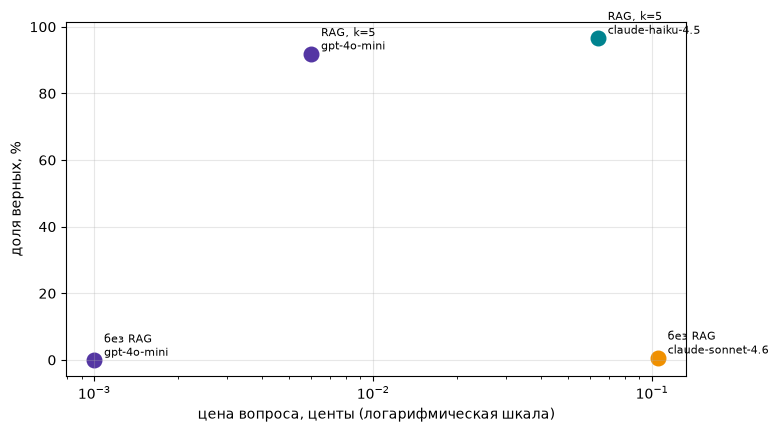

In [27]:
money_chart(table, "img/money_rag.png");

### 3.2 Агент с инструментом `knowledge_base` (код инструмента в `tools/kb.py`, тесты в `tests/test_kb.py`)

In [28]:
from tools import TOOLS, register, KBArgs, configure, knowledge_base

def run_tool(call):
    name = call["function"]["name"]
    try:
        spec = TOOLS[name]
        result = spec["fn"](**spec["args"].model_validate_json(call["function"]["arguments"]).model_dump())
    except Exception as e:
        result = f"ошибка инструмента {name}: {e}"
    return {"role": "tool", "tool_call_id": call["id"], "content": str(result)[:3000]}

AGENT_SYSTEM = ("You answer questions about events of 2026. Never answer from memory: look facts up with the tools, do not repeat the same call. "
                "When done, write the last line as FINAL: <short answer>, or NOT_FOUND if the knowledge base has no answer.")

def agent(question, model, max_steps=6):
    messages, seen, before = [{"role": "system", "content": AGENT_SYSTEM}, {"role": "user", "content": question}], set(), ledger.mine
    schemas = [t["schema"] for t in TOOLS.values()]
    for step in range(max_steps):
        msg = chat(messages, model, tools=schemas, tag="agent")
        messages.append(msg)
        calls = msg.get("tool_calls") or []
        keys = {(c["function"]["name"], c["function"]["arguments"]) for c in calls}
        if not calls or keys & seen or step == max_steps - 1:
            break
        seen |= keys
        messages += [run_tool(c) for c in calls]
    if calls:
        messages += [{"role": "tool", "tool_call_id": c["id"], "content": "call rejected: answer from what you already have"} for c in calls]
        msg = chat(messages, model, tag="agent")
    searches = sum(m.get("role") == "tool" for m in messages if isinstance(m, dict))
    return {"answer": msg.get("content") or "", "hits": [], "cost": ledger.mine - before, "searches": searches}


In [29]:
configure(lambda query, k, flt: search_milvus("lines", query, k, flt))


In [30]:
register(knowledge_base, KBArgs, "Searches the local knowledge base of 2026 events and returns the five closest facts with their page and section")
out = agent(tasks[3]["question"], MODELS["cheap"])
print(out["answer"], "| эталон:", tasks[3]["answer"], "| обращений к базе:", out["searches"], "| цена, центов:", round(out["cost"] * 100, 4))

In March 2026, Ukraine and Romania signed a strategic partnership agreement in the defense and energy sectors. 

FINAL: strategic partnership agreement in defense and energy sectors | эталон: a strategic partnership agreement | обращений к базе: 1 | цена, центов: 0.0118


,config,model,n,accuracy,cost_per_task,cost_per_correct
0,"RAG, k=5",gpt-4o-mini,149,0.91946,0.00006,0.00007
1,агент с инструментом,gpt-4o-mini,149,0.93960,0.00014,0.00015


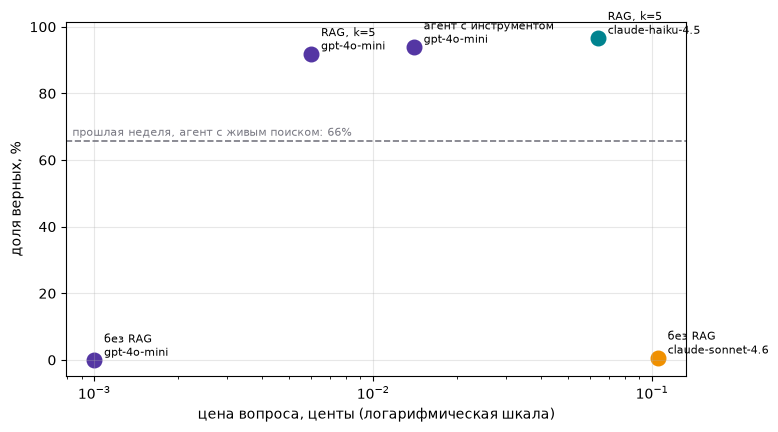

In [31]:
agent_results = evaluate(agent, sample, "агент с инструментом", MODELS["cheap"])
always = results[(results["config"] == "RAG, k=5") & (results["model"] == "gpt-4o-mini")]
final_table = report(pd.concat([results, agent_results], ignore_index=True))
last_week = float(np.mean([t["agent_ok"] for t in sample]))
money_chart(final_table, "img/money_all.png", baseline=(f"прошлая неделя, агент с живым поиском: {last_week:.0%}", last_week))
report(pd.concat([always, agent_results], ignore_index=True))

In [32]:
final_table

,config,model,n,accuracy,cost_per_task,cost_per_correct
0,без RAG,gpt-4o-mini,149,0.00000,0.00001,NaN
1,без RAG,claude-sonnet-4.6,149,0.00671,0.00105,0.15658
2,"RAG, k=5",gpt-4o-mini,149,0.91946,0.00006,0.00007
3,"RAG, k=5",claude-haiku-4.5,149,0.96644,0.00064,0.00066
4,агент с инструментом,gpt-4o-mini,149,0.93960,0.00014,0.00015


In [33]:
pd.concat([results, agent_results], ignore_index=True).to_csv("results_raw.csv", index=False)


### 3.3 Отказы: 10 вопросов без ответа

In [34]:
UNANSWERABLE = [t["question"] for t in load_jsonl("unanswerable_2026.jsonl")]
refusals = [rag_answer(q, MODELS["cheap"]) for q in UNANSWERABLE]
sum("NOT_FOUND" in r["answer"] for r in refusals), [final_answer(r["answer"])[:40] for r in refusals if "NOT_FOUND" not in r["answer"]]

(10, [])

In [99]:
rows = []
for name, fn, model, df in [("RAG, дешёвая", rag_answer, MODELS["cheap"], results[(results["config"] == "RAG, k=5") & (results["model"] == "gpt-4o-mini")]),
                            ("RAG, средняя", rag_answer, MODELS["mid"], results[(results["config"] == "RAG, k=5") & (results["model"] == "claude-haiku-4.5")]),
                            ("агент с knowledge_base", agent, MODELS["cheap"], agent_results)]:
    rows.append({"конфигурация": name, "отказов из 10 без ответа": sum("NOT_FOUND" in fn(q, model)["answer"] for q in UNANSWERABLE),
                 "зря отказов из 149 с ответом": int((df["refused"] & ~df["correct"]).sum())})
pd.DataFrame(rows)


,конфигурация,отказов из 10 без ответа,зря отказов из 149 с ответом
0,"RAG, дешёвая",10,8
1,"RAG, средняя",10,2
2,агент с knowledge_base,10,1


(0.76, 0.603)

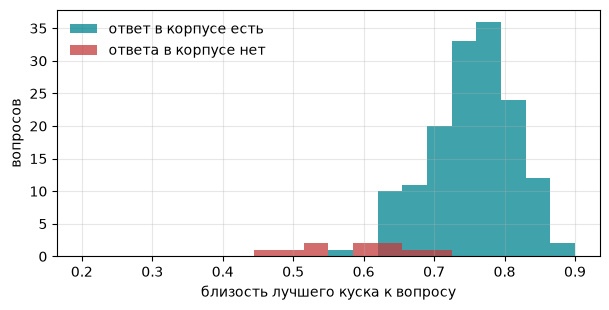

In [35]:
top_answerable = [search_numpy(q, line_vecs, 1)[0][1] for q in q_vecs]
top_unanswerable = [r["hits"][0]["score"] for r in refusals]
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(top_answerable, bins=20, range=(0.2, 0.9), alpha=0.75, color=COLORS["teal"], label="ответ в корпусе есть")
ax.hist(top_unanswerable, bins=20, range=(0.2, 0.9), alpha=0.75, color=COLORS["red"], label="ответа в корпусе нет")
ax.set_xlabel("близость лучшего куска к вопросу"); ax.set_ylabel("вопросов"); ax.legend(frameon=False); ax.grid(alpha=0.3)
round(float(np.median(top_answerable)), 3), round(float(np.median(top_unanswerable)), 3)

### 3.4 Разбор провалов: «поиск не нашёл» и «нашёл, но ответ неверный»

In [36]:
def diagnose(results):
    wrong = results[~results["correct"] & results["config"].str.startswith("RAG")]
    return wrong.groupby("model").agg(не_нашли=("found", lambda s: int((~s).sum())), нашли_но_ответ_неверный=("found", "sum"))

diagnose(results)

,не_нашли,нашли_но_ответ_неверный
model,,
claude-haiku-4.5,1,4
gpt-4o-mini,1,11


In [37]:
results[~results["correct"] & (results["config"] == "RAG, k=5")][["model", "gold", "answer", "found"]]

,model,gold,answer,found
300,gpt-4o-mini,Miguel Díaz-Canel,NOT_FOUND.,False
326,gpt-4o-mini,43,46,True
358,gpt-4o-mini,13 years,NOT_FOUND,True
383,gpt-4o-mini,José Jerí,NOT_FOUND,True
396,gpt-4o-mini,"252,756 miles","252,757 miles (406,773 km).",True
403,gpt-4o-mini,2026 Beninese parliamentary election,Beninese parliamentary election.,True
405,gpt-4o-mini,conspiracy to commit arson,Attack on Jewish sites.,True
422,gpt-4o-mini,Paris St-Germain,NOT_FOUND,True
437,gpt-4o-mini,30.2%,NOT_FOUND,True
438,gpt-4o-mini,Koblenz,NOT_FOUND,True


### 3.5 Расход

In [38]:
ledger.table(), round(ledger.total, 3)

(                              calls  prompt  completion     cost
 tag   model                                                     
 agent gpt-4o-mini               313  103074       10057  0.02142
 embed text-embedding-3-small    172    1906           0  0.00004
 plain claude-sonnet-4.6         149    8592        8720  0.15658
       gpt-4o-mini               149    8344        1240  0.00200
 rag   claude-haiku-4.5          149   48587        9293  0.09505
       gpt-4o-mini               160   46327        5006  0.00995,
 0.285)

## Шаг 4. Память агента (эпизодическая и семантическая)

### 4.1 Две памяти

Эпизодическая: журнал реплик `episodes.jsonl` (сессия, время, роль), в контекст не идёт. Семантическая: факты о пользователе в отдельной коллекции Milvus `facts`; код хранения и поиска в `tools/memory.py`, тесты без модели в `tests/test_memory.py`. Новый факт, отменяющий старый, заменяет его: модель возвращает обновлённый список целиком, а коллекция пересоздаётся.

In [39]:
from tools.memory import JOURNAL, FACTS_FILE, known_facts, store_facts, remember_episode, recall_facts, configure as configure_memory

FACTS_SYSTEM = ("Ты ведёшь память ассистента о пользователе. Верни один JSON-объект вида {\"facts\": [\"...\"]}: полный обновлённый список "
                "коротких фактов о пользователе. Добавь новые устойчивые факты: имя, город, работа, интересы, пожелания к ответам. "
                "Если новый факт отменяет старый, замени старый. Разовые вопросы и мелочи не записывай.")
ASSISTANT_SYSTEM = ("Ты помощник, который отвечает на вопросы о событиях 2026 года по базе знаний. Отвечай на языке пользователя, "
                    "опирайся на источники и на то, что знаешь о пользователе. Источники подобраны автоматически и могут быть не по теме: "
                    "используй только те, что относятся к вопросу. Если в источниках ответа нет, так и скажи.")

class Facts(BaseModel):
    facts: list[str] = Field(description="короткие факты о пользователе")

def json_from(text):
    m = re.search(r"\{.*\}", text or "", re.S)
    cleaned = re.sub(r'(\\["\\/bfnrtu])|\\', lambda e: e.group(1) or "\\\\", m.group(0) if m else "{}")
    return json.loads(cleaned, strict=False)

configure_memory(index=index_to_milvus, search=search_milvus, embed=embed_cached, has_collection=client.has_collection)

for path in (JOURNAL, FACTS_FILE):
    path.unlink(missing_ok=True)
if client.has_collection("facts"):
    client.drop_collection("facts")

### 4.2 Извлечение фактов в конце сессии (дешёвая модель)

In [40]:
def extract_facts(dialog, known):
    prompt = f"Известные факты: {json.dumps(known, ensure_ascii=False)}\n\nДиалог:\n{dialog}"
    msg = chat([{"role": "system", "content": FACTS_SYSTEM}, {"role": "user", "content": prompt}], MODELS['cheap'], tag="memory")
    return Facts.model_validate(json_from(msg["content"])).facts
    


### 4.3 Диалог с памятью

In [41]:
def search_with_memory(user_text, facts, k=5):
    plain = search_milvus("lines", user_text, k)
    personal = search_milvus("lines", user_text + " " + " ".join(facts), k) if facts else []
    by_id = {h["id"]: h for h in plain + personal}
    return [by_id[i] for i in rrf([[h["id"] for h in plain], [h["id"] for h in personal]], k)]

def talk(session, history, user_text, mode="память"):
    remember_episode(session, "user", user_text)
    facts = recall_facts(user_text) if mode == "память" else []
    hits = search_with_memory(user_text, facts) if "?" in user_text else []
    sources = "\n".join(f"[{i + 1}] ({h['page']}) {h['text']}" for i, h in enumerate(hits)) or "нет"
    system = ASSISTANT_SYSTEM + ("\nЧто известно о пользователе: " + "; ".join(facts) if facts else "")
    window = history[-4:] if mode == "память" else history
    msg = chat([{"role": "system", "content": system}] + window + [{"role": "user", "content": f"Источники:\n{sources}\n\n{user_text}"}],
               MODELS["cheap"], tag=f"dialog: {mode}")
    answer = msg.get("content") or ""
    history += [{"role": "user", "content": user_text if mode == "память" else f"Источники:\n{sources}\n\n{user_text}"}, {"role": "assistant", "content": answer}]
    remember_episode(session, "assistant", answer)
    return answer

def end_session(history):
    dialog = "\n".join(f"{m['role']}: {m['content'][:400]}" for m in history)
    store_facts(extract_facts(dialog, known_facts()))
    return known_facts()

### 4.4 Две сессии: первая рассказывает о себе, вторая использует факты и меняет два из них

In [42]:
first = []
print(talk("s1", first, "Привет! Меня зовут Олег, я SDET из Москвы: пишу автотесты и ломаю чужие сервисы. Обожаю Формулу 1, слежу за ИИ и сбоями сервисов, отвечай коротко и по делу."))
print(talk("s1", first, "Кто выиграл Australian Grand Prix 2026 в Формуле 1?"))
end_session(first)

Привет, Олег! К сожалению, у меня нет информации о событиях 2026 года. Если у тебя есть конкретные вопросы или темы, которые тебя интересуют, дай знать!
В 2026 году Australian Grand Prix выиграл Джордж Рассел.


['Имя: Олег',
 'Город: Москва',
 'Работа: SDET',
 'Интересы: Формула 1, ИИ, сбои сервисов',
 'Пожелания к ответам: коротко и по делу']

In [43]:
second = []
print(talk("s2", second, "Что интересного случилось в моих темах за год?"))
print(talk("s2", second, "Формула 1 мне надоела, теперь слежу за футболом. И я переехал в Берлин."))
print(talk("s2", second, "Кто победил на чемпионате мира по футболу 2026?"))
end_session(second)

В 2026 году в ваших интересах произошло несколько значительных событий:

1. **Формула 1**: Информация о событиях в Формуле 1 в 2026 году отсутствует в доступных источниках.

2. **Искусственный интеллект**: В 2026 году наблюдался значительный прогресс в области ИИ, включая автономные кибератаки, проведенные агентами ИИ OpenAI во время тестов по кибербезопасности. Это привело к тому, что крупные компании начали уделять больше внимания безопасности и согласованию своих моделей.

3. **Сбои сервисов**: Конкретные данные о сбоях сервисов в 2026 году отсутствуют, но учитывая активное развитие ИИ, можно предположить, что вопросы кибербезопасности и возможные сбои могли быть актуальными.

Если вас интересуют более конкретные события или детали, дайте знать!
Понял, спасибо за обновление! В 2026 году в футболе произошло несколько интересных событий:

1. **Чемпионат мира по футболу**: В 2026 году прошел Чемпионат мира по футболу, который состоялся в США, Канаде и Мексике. Это был первый чемпионат,

['Имя: Олег',
 'Город: Берлин',
 'Работа: SDET',
 'Интересы: Футбол, ИИ, сбои сервисов',
 'Пожелания к ответам: коротко и по делу']

### 4.5 Журнал реплик

In [44]:
print(JOURNAL.read_text(encoding="utf-8")[:1200])

{"session": "s1", "time": "2026-10-13 19:14:46", "role": "user", "text": "Привет! Меня зовут Олег, я SDET из Москвы: пишу автотесты и ломаю чужие сервисы. Обожаю Формулу 1, слежу за ИИ и сбоями сервисов, отвечай коротко и по делу."}
{"session": "s1", "time": "2026-10-13 19:14:48", "role": "assistant", "text": "Привет, Олег! К сожалению, у меня нет информации о событиях 2026 года. Если у тебя есть конкретные вопросы или темы, которые тебя интересуют, дай знать!"}
{"session": "s1", "time": "2026-10-13 19:14:48", "role": "user", "text": "Кто выиграл Australian Grand Prix 2026 в Формуле 1?"}
{"session": "s1", "time": "2026-10-13 19:14:51", "role": "assistant", "text": "В 2026 году Australian Grand Prix выиграл Джордж Рассел."}
{"session": "s2", "time": "2026-10-13 19:14:58", "role": "user", "text": "Что интересного случилось в моих темах за год?"}
{"session": "s2", "time": "2026-10-13 19:15:04", "role": "assistant", "text": "В 2026 году в ваших интересах произошло несколько значительных со

### 4.6 Токены: вся история в контексте против окна из четырёх сообщений и фактов (10 реплик)

,prompt,cost
tag,,
dialog: память,5123,0.00117
dialog: вся история,16731,0.00244


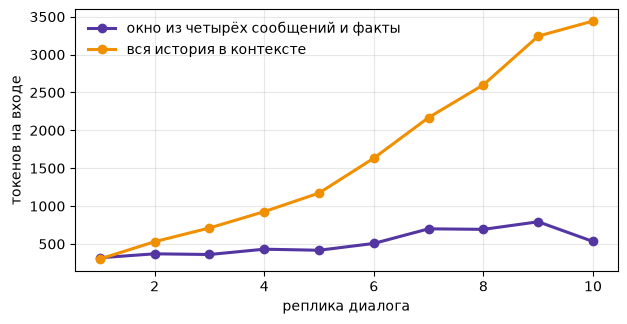

In [45]:
SCRIPT = ["Кто выиграл Australian Grand Prix 2026 в Формуле 1?", "А кто победил на Barcelona-Catalunya Grand Prix?", "Когда Abu Dhabi Grand Prix?",
          "Что случилось с Telstra 8 июля?", "Какие ещё были сбои и outage в 2026 году?", "Что было на AI Impact Summit в Нью-Дели?",
          "Что случилось с миссией PROBA-3?", "Что известно про облёт Луны миссией Artemis II?",
          "Кто победил на чемпионате мира по футболу 2026?", "Подведи итог: о чём мы говорили?"]
for mode in ("память", "вся история"):
    history = []
    for q in SCRIPT:
        talk("bench", history, q, mode)
per_turn = pd.DataFrame([c for c in ledger.calls if c["tag"].startswith("dialog: ")][-2 * len(SCRIPT):])
fig, ax = plt.subplots(figsize=(7, 3.4))
for (tag, part), color in zip(per_turn.groupby("tag", sort=False), [COLORS["violet"], COLORS["amber"]]):
    ax.plot(range(1, len(part) + 1), part["prompt"].values, marker="o", lw=2.2, color=color,
            label={"dialog: память": "окно из четырёх сообщений и факты", "dialog: вся история": "вся история в контексте"}[tag])
ax.set_xlabel("реплика диалога"); ax.set_ylabel("токенов на входе"); ax.legend(frameon=False); ax.grid(alpha=0.3)
fig.savefig("img/memory_tokens.png", dpi=150, bbox_inches="tight")
per_turn.groupby("tag", sort=False).agg(prompt=("prompt", "sum"), cost=("cost", "sum")).round(5)

## Шаг 5. Нарезка по абзацам (дополнительно)

В Википедии дата часто стоит отдельной короткой строкой («8 March»), а события под ней идут строками без даты. Нарезка по строкам такие короткие строки выбрасывает, и у 55% событий дата теряется. Абзац здесь это дата вместе со всеми её событиями; событие, которое начинается с даты, остаётся отдельным куском. Смотрим recall@k и RAG на таких кусках.

### 5.1 Нарезка, эмбеддинги, индекс `paragraphs`

In [100]:
MONTH = "January|February|March|April|May|June|July|August|September|October|November|December"
DAY_ONLY = re.compile(rf"^(?:\d{{1,2}}(?:[–-]\d{{1,2}})?\s+(?:{MONTH})|(?:{MONTH})\s+\d{{1,2}}(?:[–-]\d{{1,2}})?)$")
DAY_START = re.compile(rf"^(?:\d{{1,2}}(?:[–-]\d{{1,2}})?\s+(?:{MONTH})\b|(?:{MONTH})\s+\d{{1,2}}\b)")

def chunk_paragraphs(page):
    chunks, section, day, events = [], "", "", []
    def flush():
        nonlocal events
        text = " ".join(events)
        if len(text) > 40:
            chunks.append({"page": page["page"], "section": section, "url": page["url"], "text": f"{day}: {text}" if day else text})
        events = []
    for line in (" ".join(l.split()) for l in page["text"].splitlines() if l.strip()):
        if line.startswith("="):
            flush()
            section, day = line.strip("= "), ""
        elif DAY_ONLY.match(line):
            flush()
            day = line
        elif DAY_START.match(line):
            flush()
            day, events = "", [line]
            flush()
        elif day:
            events.append(line)
        else:
            events = [line]
            flush()
    flush()
    return chunks

para_chunks = [c for p in corpus for c in chunk_paragraphs(p)]
para_vecs = embed_cached([emb_text(c) for c in para_chunks])
save_cache()
index_to_milvus("paragraphs", para_chunks, para_vecs)
koblenz = next(c for c in para_chunks if "Koblenz" in c["text"])
len(para_chunks), round(np.mean([len(c["text"]) for c in para_chunks])), koblenz


(4738,
 176,
 {'page': '2026 in Germany',
  'section': 'March',
  'url': 'https://en.wikipedia.org/wiki/2026_in_Germany',
  'text': '8 March: 2026 Baden-Württemberg state election: The Greens win a plurality of 30.2% in the Landtag of Baden-Württemberg, the CDU win 29,7% and the AfD win 18.8% in the Landtag. A meteorite strikes a roof of a house in Koblenz, Rhineland-Palatinate. No one is injured.'})

### 5.2 recall@k: строки, 400 символов, абзацы

,по строкам,по 400 символов,по абзацам
1,0.899,0.550,0.893
3,0.980,0.738,0.960
5,0.987,0.805,0.966
10,0.987,0.846,0.973


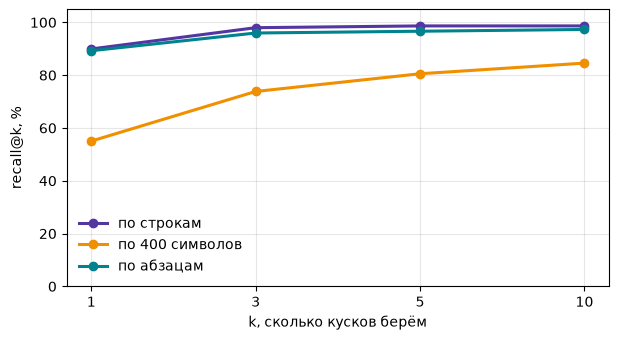

In [101]:
curves3 = {"по строкам": curves["по строкам"], "по 400 символов": curves["по 400 символов"],
           "по абзацам": recall_curve(para_chunks, para_vecs)}
fig, ax = plt.subplots(figsize=(7, 3.6))
for (name, curve), color in zip(curves3.items(), [COLORS["violet"], COLORS["amber"], COLORS["teal"]]):
    ks = [k for k in curve if k <= 10]
    ax.plot([str(k) for k in ks], [curve[k] * 100 for k in ks], marker="o", lw=2.2, color=color, label=name)
ax.set_xlabel("k, сколько кусков берём"); ax.set_ylabel("recall@k, %"); ax.set_ylim(0, 105); ax.legend(frameon=False); ax.grid(alpha=0.3)
fig.savefig("img/recall_paragraphs.png", dpi=150, bbox_inches="tight")
pd.DataFrame(curves3).loc[[1, 3, 5, 10]].round(3)


### 5.3 RAG по абзацам против RAG по строкам (дешёвая и средняя модель, 149 вопросов)

In [102]:
para_results = pd.concat([evaluate(lambda q, m: rag_answer(q, m, 5, "paragraphs"), sample, "RAG по абзацам, k=5", MODELS[x]) for x in ("cheap", "mid")], ignore_index=True)
lines_rag = results[results["config"] == "RAG, k=5"]
report(pd.concat([lines_rag, para_results], ignore_index=True))


,config,model,n,accuracy,cost_per_task,cost_per_correct
0,"RAG, k=5",gpt-4o-mini,149,0.91946,0.00006,0.00007
1,"RAG, k=5",claude-haiku-4.5,149,0.96644,0.00064,0.00066
2,"RAG по абзацам, k=5",gpt-4o-mini,149,0.90604,0.00007,0.00008
3,"RAG по абзацам, k=5",claude-haiku-4.5,149,0.94631,0.00071,0.00075


### 5.4 Отказы и что изменилось по сравнению со строками (дешёвая модель)

In [103]:
para_refusals = [rag_answer(q, MODELS["cheap"], 5, "paragraphs") for q in UNANSWERABLE]
cheap = lambda df: df[df["model"] == "gpt-4o-mini"]
wrong_lines = set(cheap(lines_rag).query("~correct")["id"])
wrong_para = set(cheap(para_results).query("~correct")["id"])
{"отказов из 10 без ответа": sum("NOT_FOUND" in r["answer"] for r in para_refusals),
 "зря отказов, абзацы": int(cheap(para_results).eval("refused & ~correct").sum()), "зря отказов, строки": int(cheap(lines_rag).eval("refused & ~correct").sum()),
 "ошибок, строки": len(wrong_lines), "ошибок, абзацы": len(wrong_para), "исправилось": len(wrong_lines - wrong_para), "сломалось": len(wrong_para - wrong_lines),
 "найден верный кусок, абзацы": float(cheap(para_results)["found"].mean())}


{'отказов из 10 без ответа': 10,
 'зря отказов, абзацы': 11,
 'зря отказов, строки': 8,
 'ошибок, строки': 12,
 'ошибок, абзацы': 14,
 'исправилось': 6,
 'сломалось': 8,
 'найден верный кусок, абзацы': 0.9664429530201343}

### 5.5 Что стало с вопросами, на которые дешёвая модель зря отвечала NOT_FOUND

In [104]:
para_results.to_csv("results_paragraphs.csv", index=False)
refused_lines = lines_rag.query("model == 'gpt-4o-mini' and refused and ~correct")["id"]
cheap(para_results).set_index("id").loc[refused_lines, ["gold", "answer", "found", "correct"]]


,gold,answer,found,correct
id,,,,
fresh-2,Miguel Díaz-Canel,NOT_FOUND,False,False
fresh-60,13 years,13 years.,True,True
fresh-85,José Jerí,NOT_FOUND,True,False
fresh-124,Paris St-Germain,NOT_FOUND,True,False
fresh-139,30.2%,30.2%,True,True
fresh-140,Koblenz,Koblenz,True,True
fresh-147,Tomahawk missiles,Tomahawk missiles.,True,True
fresh-148,28 July,NOT_FOUND,True,False
